# SAM3-I：GitHub 自动部署、单图推理与编号展示

只需本 notebook、自己的 Google Drive 权重和一张图片。代码自动从 [GitHub 仓库](https://github.com/xheihex/SAM3-I) 下载；不需要上传源码 ZIP。作者的模型源码保持原样，沿用已验证的单图推理脚本。

2026-11-03 提供的运行记录已确认：Colab metadata 为 A100，BF16 / simple / 阈值 0.6 输出 1 个实例，PyTorch 峰值已分配显存约 7.64 GiB。该记录尚未执行最后的云盘保存步骤，也未完整留存子进程日志和实例分数。新版将保存日志，并在推理完成的同一单元格自动保存结果到 Drive。

先选择 GPU 运行时，再按顺序执行。图上显示框、半透明掩码和从 **1** 开始的编号；**图下方显示每个编号的置信度**。默认提示沿用已验证的简单指令。

## 1. 从 GitHub 下载源码

先运行两个折叠的辅助单元格，再运行下载单元格。它们仅定义部署与展示函数，不加载模型。默认下载 `main`；需要重现某一版本时可将 `GIT_REF` 改为完整提交号。每次创建独立 checkout，实际提交号会随结果保存。

In [1]:
# @title 部署辅助函数（运行一次）
"""Colab deployment helpers, mirrored into the standalone notebook."""
from __future__ import annotations

import hashlib
import json
import os
from pathlib import Path
import shutil
import subprocess
from datetime import datetime, timezone


def run_logged(command, log_path, *, env=None, cwd=None, echo=True):
    """Print subprocess output into the notebook and keep the same text on disk."""
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with log_path.open("w", encoding="utf-8") as log:
        log.write(json.dumps([str(arg) for arg in command], ensure_ascii=False) + "\n")
        log.flush()
        with subprocess.Popen(
            command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, encoding="utf-8", errors="replace", bufsize=1, env=env, cwd=cwd,
        ) as process:
            for line in process.stdout:
                if echo:
                    print(line, end="", flush=True)
                log.write(line)
                log.flush()
            returncode = process.wait()
    if returncode:
        print(f"Command failed; log: {log_path}", flush=True)
        raise subprocess.CalledProcessError(returncode, command)
    return log_path


def checkout_github(repo_url, ref, destination, logs_dir):
    """Download a branch/tag/commit into a fresh, detached Git checkout."""
    destination = Path(destination)
    if destination.exists():
        raise FileExistsError(f"Use a new checkout directory: {destination}")
    if not ref.strip() or ref.startswith("-"):
        raise ValueError("Git ref must be a nonempty branch, tag, or commit.")
    logs_dir = Path(logs_dir)
    run_logged(["git", "init", str(destination)], logs_dir / "git-init.log")
    run_logged(["git", "-C", str(destination), "remote", "add", "origin", repo_url],
               logs_dir / "git-remote.log")
    run_logged(["git", "-C", str(destination), "fetch", "--depth", "1", "origin", ref],
               logs_dir / "git-fetch.log")
    run_logged(["git", "-C", str(destination), "checkout", "--detach", "FETCH_HEAD"],
               logs_dir / "git-checkout.log")
    commit = subprocess.check_output(
        ["git", "-C", str(destination), "rev-parse", "HEAD"], text=True,
    ).strip()
    required = ("pyproject.toml", "uv.lock", ".python-version",
                "scripts/colab_single_image.py", "scripts/audit_single_image_checkpoint.py",
                "sam3/assets/bpe_simple_vocab_16e6.txt.gz")
    for name in required:
        if not (destination / name).is_file():
            raise FileNotFoundError(f"GitHub revision lacks required file: {name}")
    source = {
        "repository": repo_url, "requested_ref": ref, "git_commit": commit,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "runtime_file_sha256": {
            name: hashlib.sha256((destination / name).read_bytes()).hexdigest()
            for name in required
        },
    }
    print(f"GitHub revision: {commit}", flush=True)
    return destination, source


def ensure_local_checkpoint(source, destination):
    """Reuse a complete local copy only while the source metadata still matches."""
    source, destination = Path(source), Path(destination)
    if not source.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {source}")
    source_stat = source.stat()
    fingerprint = {
        "source_path": str(source.resolve()), "size_bytes": source_stat.st_size,
        "mtime_ns": source_stat.st_mtime_ns,
    }
    if source.resolve() == destination.resolve():
        return fingerprint
    destination.parent.mkdir(parents=True, exist_ok=True)
    metadata_path = destination.with_suffix(destination.suffix + ".source.json")
    if destination.is_file() and metadata_path.is_file():
        previous = json.loads(metadata_path.read_text())
        if previous == fingerprint and destination.stat().st_size == source_stat.st_size:
            print("Reusing local checkpoint; Drive source metadata is unchanged.", flush=True)
            return fingerprint
    if shutil.disk_usage(destination.parent).free < source_stat.st_size + 1024**3:
        raise RuntimeError("Insufficient local disk space for checkpoint copy + 1 GiB.")
    partial = destination.with_suffix(destination.suffix + ".part")
    print("Copying checkpoint from Drive to local disk...", flush=True)
    shutil.copy2(source, partial)
    if partial.stat().st_size != source_stat.st_size:
        raise RuntimeError("Incomplete local checkpoint copy.")
    partial.replace(destination)
    metadata_path.write_text(json.dumps(fingerprint, indent=2), encoding="utf-8")
    return fingerprint


def render_saved_results(output_dir, image_path, source, overlay_renderer, figure_renderer):
    """Add stable IDs and presentation artifacts to old or new inference outputs."""
    import numpy as np
    from PIL import Image

    output_dir = Path(output_dir)
    result_path = output_dir / "result.json"
    result = json.loads(result_path.read_text())
    predictions = result["predictions"]
    with Image.open(image_path) as opened:
        image = opened.convert("RGB")
    if (result["width"], result["height"]) != image.size:
        raise ValueError("Result dimensions do not match the uploaded image.")
    masks = np.empty((len(predictions), image.height, image.width), dtype=bool)
    for index, prediction in enumerate(predictions):
        # Keep the saved prediction order and mask filenames; only add one-based IDs.
        prediction["instance_id"] = index + 1
        mask_path = (output_dir / prediction["mask_file"]).resolve()
        if not mask_path.is_relative_to(output_dir.resolve()):
            raise ValueError("Mask file must be inside the result directory.")
        with Image.open(mask_path) as opened_mask:
            if opened_mask.size != image.size:
                raise ValueError("Mask dimensions do not match the uploaded image.")
            masks[index] = np.asarray(opened_mask.convert("L")) > 0
    overlay = overlay_renderer(image, masks, predictions)
    overlay.save(output_dir / "overlay.png")
    figure = figure_renderer(overlay, predictions)
    figure.save(output_dir / "result_figure.png")
    result["source"] = source
    result["visualization"] = {
        "instance_id_start": 1, "overlay": "overlay.png", "figure": "result_figure.png",
        "description": "Colored masks, boxes and IDs; confidence scores below the image.",
    }
    result_path.write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    return result, figure


def archive_run(output_dir, source, audit_path, logs_dir, environment_path, drive_results):
    """Save provenance and logs with results, then immediately persist a ZIP to Drive."""
    output_dir, drive_results = Path(output_dir), Path(drive_results)
    (output_dir / "source-manifest.json").write_text(
        json.dumps(source, ensure_ascii=False, indent=2), encoding="utf-8",
    )
    shutil.copy2(audit_path, output_dir / "checkpoint-audit.json")
    shutil.copy2(environment_path, output_dir / "environment.json")
    shutil.copytree(logs_dir, output_dir / "logs", dirs_exist_ok=True)
    archive = Path(shutil.make_archive(str(output_dir), "zip", root_dir=output_dir))
    drive_results.mkdir(parents=True, exist_ok=True)
    saved_archive = drive_results / archive.name
    shutil.copy2(archive, saved_archive)
    print(f"Saved to Drive: {saved_archive}", flush=True)
    return archive, saved_archive

EMBEDDED_SOURCE_SHA256 = dict(globals().get("EMBEDDED_SOURCE_SHA256", {}))
EMBEDDED_SOURCE_SHA256['scripts/colab_notebook_helpers.py'] = '50dd1a011b77f5e14e7316efea9323547721e5a56a96786cc87e8b2f6d17e897'


In [2]:
# @title 编号与置信度展示函数（运行一次）
"""Render numbered SAM3-I instances and a confidence panel with Pillow only.

The caller supplies masks in exactly the same order as predictions. Instance
identifiers are one-based and remain the same in the overlay and score panel.
"""
from __future__ import annotations

import colorsys
import math

import numpy as np
from PIL import Image, ImageDraw, ImageFont


def instance_color(instance_id: int) -> tuple[int, int, int]:
    """Return a stable, bright RGB color for a one-based instance identifier."""
    if not isinstance(instance_id, int) or instance_id < 1:
        raise ValueError("instance_id must be a positive integer")
    hue = ((instance_id - 1) * 0.618033988749895 + 0.02) % 1.0
    return tuple(round(channel * 255) for channel in colorsys.hsv_to_rgb(hue, 0.78, 0.98))


def _font(size: int, bold: bool = False):
    names = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]
    for name in names:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            continue
    return ImageFont.load_default(size=size)


def _validate_predictions(predictions):
    identifiers = []
    for prediction in predictions:
        instance_id = prediction["instance_id"]
        instance_color(instance_id)
        identifiers.append(instance_id)
        score = float(prediction["score"])
        if not math.isfinite(score) or not 0 <= score <= 1:
            raise ValueError("Prediction scores must be finite and in [0, 1].")
        box = prediction["box_xyxy"]
        if len(box) != 4 or not all(math.isfinite(float(value)) for value in box):
            raise ValueError("Prediction box_xyxy must contain four finite coordinates.")
    if len(set(identifiers)) != len(identifiers):
        raise ValueError("Instance identifiers must be unique.")


def _label_origin(box, badge_size, occupied, image_size):
    x0, y0, x1, y1 = box
    badge_width, badge_height = badge_size
    width, height = image_size
    candidates = [(x0, y0), (x1 - badge_width, y0),
                  (x0, y1 - badge_height), (x1 - badge_width, y1 - badge_height)]
    def clipped(candidate):
        return (max(0, min(width - badge_width, round(candidate[0]))),
                max(0, min(height - badge_height, round(candidate[1]))))
    def overlap(origin):
        x, y = origin
        return sum(max(0, min(x + badge_width, right) - max(x, left))
                   * max(0, min(y + badge_height, bottom) - max(y, top))
                   for left, top, right, bottom in occupied)
    origin = min((clipped(candidate) for candidate in candidates), key=overlap)
    occupied.append((origin[0], origin[1], origin[0] + badge_width, origin[1] + badge_height))
    return origin


def render_overlay(image: Image.Image, masks: np.ndarray, predictions: list[dict]) -> Image.Image:
    """Return original-size RGB image with translucent masks, boxes and IDs.

    No confidence values are drawn over the photograph; they belong in the panel
    returned by render_result_figure.
    """
    _validate_predictions(predictions)
    masks = np.asarray(masks)
    if masks.ndim == 4 and masks.shape[1] == 1:
        masks = masks[:, 0]
    width, height = image.size
    if masks.shape != (len(predictions), height, width):
        raise ValueError("Masks must have shape [K,H,W] or [K,1,H,W] matching the image.")
    overlay = image.convert("RGB")
    for mask, prediction in zip(masks, predictions):
        alpha = Image.fromarray(np.asarray(mask, dtype=np.uint8) * 88)
        overlay.paste(instance_color(prediction["instance_id"]), (0, 0, width, height), alpha)

    draw = ImageDraw.Draw(overlay)
    scale = width / 1200
    line_width = max(2, round(3 * scale))
    font_size = max(13, round(24 * scale))
    font = _font(font_size, bold=True)
    pad = max(3, round(5 * scale))
    occupied = []
    for prediction in predictions:
        color = instance_color(prediction["instance_id"])
        raw_box = [float(value) for value in prediction["box_xyxy"]]
        x0, x1 = sorted((max(0, min(width - 1, raw_box[0])),
                         max(0, min(width - 1, raw_box[2]))))
        y0, y1 = sorted((max(0, min(height - 1, raw_box[1])),
                         max(0, min(height - 1, raw_box[3]))))
        box = (x0, y0, x1, y1)
        draw.rectangle(box, outline=color, width=line_width)
        label = str(prediction["instance_id"])
        text_box = draw.textbbox((0, 0), label, font=font)
        badge_width = min(width, text_box[2] - text_box[0] + 2 * pad)
        badge_height = min(height, text_box[3] - text_box[1] + 2 * pad)
        x, y = _label_origin(box, (badge_width, badge_height), occupied, image.size)
        draw.rounded_rectangle((x, y, x + badge_width - 1, y + badge_height - 1),
                               radius=max(2, round(3 * scale)), fill=color,
                               outline=(255, 255, 255), width=max(1, round(scale)))
        # Dark text stays readable on the bright instance-color badge.
        draw.text((x + pad - text_box[0], y + pad - text_box[1]),
                  label, font=font, fill=(15, 23, 42))
    return overlay


def render_result_figure(
    overlay: Image.Image,
    predictions: list[dict],
    *,
    max_width: int = 1200,
) -> Image.Image:
    """Return a display-size RGB figure with the confidence panel below the image.

    The original-size overlay can be saved separately. This combined artifact
    uses at most max_width pixels across so its labels remain readable when
    displayed in Colab, including a score table with many instances.
    """
    _validate_predictions(predictions)
    if max_width < 160:
        raise ValueError("max_width must be at least 160 pixels.")
    width = min(max_width, max(320, overlay.width))
    height = max(1, round(overlay.height * width / overlay.width))
    photo = overlay.convert("RGB").resize((width, height), Image.Resampling.LANCZOS)
    font_size = max(12, min(18, round(width / 60)))
    body_font = _font(font_size)
    title_font = _font(font_size + 2, bold=True)
    pad = max(10, round(width / 60))
    title_height = font_size + 2 * pad
    columns = max(1, min(4, width // 270))
    row_height = font_size + 18
    rows = max(1, math.ceil(len(predictions) / columns))
    panel_height = title_height + rows * row_height + pad
    figure = Image.new("RGB", (width, height + panel_height), (248, 250, 252))
    figure.paste(photo, (0, 0))
    draw = ImageDraw.Draw(figure)
    draw.line((0, height, width, height), fill=(203, 213, 225), width=1)
    draw.text((pad, height + pad), "Instance confidence", fill=(15, 23, 42), font=title_font)
    if not predictions:
        draw.text((pad, height + title_height + 4), "No instances above the threshold.",
                  fill=(71, 85, 105), font=body_font)
        return figure
    column_width = (width - 2 * pad) / columns
    swatch_size = max(10, font_size - 2)
    for index, prediction in enumerate(predictions):
        row, column = divmod(index, columns)
        x = round(pad + column * column_width)
        y = height + title_height + row * row_height + 4
        color = instance_color(prediction["instance_id"])
        draw.rounded_rectangle((x, y + 3, x + swatch_size, y + 3 + swatch_size),
                               radius=2, fill=color)
        text = f"#{prediction['instance_id']}  {float(prediction['score']):.4f}"
        draw.text((x + swatch_size + 8, y), text, fill=(30, 41, 59), font=body_font)
    return figure

EMBEDDED_SOURCE_SHA256 = dict(globals().get("EMBEDDED_SOURCE_SHA256", {}))
EMBEDDED_SOURCE_SHA256['scripts/single_image_visualization.py'] = 'aeb91f0a3ae756acb552d61cdffb20c15ace08a4a46d03a43dee6ddb5189acd4'


In [3]:
# @title 下载 GitHub 代码
import sys
import uuid

GITHUB_URL = "https://github.com/xheihex/SAM3-I.git" # @param {type:"string"}
GIT_REF = "main" # @param {type:"string"}
DEPLOYMENT_ID = uuid.uuid4().hex[:12]
DEPLOYMENT_DIR = Path("/content/sam3i-deployments") / DEPLOYMENT_ID
LOGS = DEPLOYMENT_DIR / "logs"
REPO, SOURCE_INFO = checkout_github(GITHUB_URL, GIT_REF, DEPLOYMENT_DIR / "SAM3-I", LOGS)
SOURCE_INFO["notebook_version"] = "2026-11-03-github-numbered-v1"
SOURCE_INFO["notebook_embedded_source_sha256"] = dict(EMBEDDED_SOURCE_SHA256)


hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/sam3i-deployments/2c155bad9c35/SAM3-I/.git/
From https://github.com/xheihex/SAM3-I
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> origin/main
HEAD is now at 35d4550 Colab单图推理部署——成功推理
GitHub revision: 35d4550346eab2a1613f15f9143c572580b097dd


## 2. 按 uv 锁文件安装，并记录实际 GPU 环境

使用独立 Python 3.12 环境；Colab 原生内核负责上传、Drive 和展示。子进程日志会同步打印并写入文件。

In [4]:
# @title 创建环境并检查 GPU
run_logged([sys.executable, "-m", "pip", "install", "-q", "uv"], LOGS / "uv-install.log")
UV = [sys.executable, "-m", "uv"]
RUN_ENV = dict(os.environ, UV_CACHE_DIR="/content/.cache/sam3i-uv",
               HF_HOME="/content/.cache/sam3i-hf", MPLCONFIGDIR="/content/.cache/sam3i-matplotlib",
               PYTHONUNBUFFERED="1", CUDA_VISIBLE_DEVICES="0")
run_logged(UV + ["sync", "--locked", "--no-dev", "--project", str(REPO)],
           LOGS / "environment-sync.log", env=RUN_ENV)
RUN = UV + ["run", "--locked", "--no-dev", "--project", str(REPO), "python"]
ENVIRONMENT_PATH = DEPLOYMENT_DIR / "environment.json"
ENV_PROBE = """import json, platform, sys
from pathlib import Path
import torch
assert torch.cuda.is_available(), "Please enable a CUDA GPU runtime"
free, total = torch.cuda.mem_get_info()
info = {
    "python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0), "capability": list(torch.cuda.get_device_capability(0)),
    "free_vram_gib": free / 2**30, "total_vram_gib": total / 2**30,
    "native_bf16": torch.cuda.is_bf16_supported(including_emulation=False),
}
Path(sys.argv[1]).write_text(json.dumps(info, indent=2), encoding="utf-8")
print(json.dumps(info, indent=2))
"""
run_logged(RUN + ["-c", ENV_PROBE, str(ENVIRONMENT_PATH)], LOGS / "gpu-environment.log", env=RUN_ENV)


Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: sam3i-deployments/2c155bad9c35/SAM3-I/.venv
Resolved 202 packages in 3ms
Prepared 90 packages in 1m 15s
Installed 90 packages in 599ms
 + absl-py==2.5.1
 + antlr4-python3-runtime==4.9.3
 + anyio==4.15.1
 + click==8.5.0
 + cloudpickle==3.1.2
 + contourpy==1.3.3
 + cycler==0.12.1
 + einops==0.8.2
 + fairscale==0.4.13
 + filelock==4.2.4
 + fonttools==4.68.0
 + fsspec==2026.9.0
 + ftfy==6.1.1
 + fvcore==0.1.5.post20221221
 + grpcio==1.85.0
 + h11==0.16.0
 + hf-xet==1.8.0
 + httpcore2==2.16.0
 + httpx2==2.16.0
 + huggingface-hub==2.4.0
 + hydra-core==1.3.8
 + idna==3.20
 + imageio==2.38.1
 + iopath==0.1.10
 + jinja2==3.1.6
 + joblib==1.6.0
 + kiwisolver==1.5.1
 + lazy-loader==0.6
 + lightning-utilities==0.15.3
 + markdown==3.11.2
 + markupsafe==3.0.4
 + matplotlib==3.11.2
 + mpmath==1.3.0
 + narwhals==2.28.0
 + networkx==3.7
 + numpy==1.26.4
 + nvidia-cublas-cu12==12.6.4.1
 + nvidia-cuda-cupti-cu12==12

PosixPath('/content/sam3i-deployments/2c155bad9c35/logs/gpu-environment.log')

## 3. 从 Google Drive 加载权重

保留你已运行成功的默认路径，可按实际位置修改。首次复制到 Colab 本地磁盘，再以内存映射读取；重新运行时，只有云盘来源路径、大小和修改时间都一致才复用本地副本。此检查用于避免重复复制，不等于权重内容校验。

In [10]:
# @title 挂载 Drive 与准备权重
from google.colab import drive
drive.mount("/content/drive")

DRIVE_CHECKPOINT = "/content/drive/MyDrive/models/sam3-i/checkpoint.pt" # @param {type:"string"}
DRIVE_RESULTS = "/content/drive/MyDrive/results/SAM3-I" # @param {type:"string"}
CHECKPOINT = Path("/content/sam3i-checkpoints/checkpoint.pt")
CHECKPOINT_INFO = ensure_local_checkpoint(DRIVE_CHECKPOINT, CHECKPOINT)
SOURCE_INFO["checkpoint_source"] = CHECKPOINT_INFO
print("Local checkpoint GiB:", round(CHECKPOINT.stat().st_size / 2**30, 3))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reusing local checkpoint; Drive source metadata is unchanged.
Local checkpoint GiB: 9.13


## 4. 检查 checkpoint 结构

仅本检查子进程隐藏 GPU，使用 meta 张量核对名称和形状；真实推理仍使用 GPU。

In [6]:
# @title 审查权重
AUDIT_PATH = DEPLOYMENT_DIR / "checkpoint-audit.json"
run_logged(RUN + [
    str(REPO / "scripts/audit_single_image_checkpoint.py"),
    "--checkpoint", str(CHECKPOINT), "--output", str(AUDIT_PATH),
], LOGS / "checkpoint-audit.log", env=dict(RUN_ENV, CUDA_VISIBLE_DEVICES=""), echo=False)
audit = json.loads(AUDIT_PATH.read_text())
print("Audit OK:", audit["ok"])
print("Forward keys:", audit["matched_state_keys"], "/", audit["expected_state_keys"])
print("Loading keys:", audit["real_checkpoint_loading_topology"]["matched_state_keys"],
      "/", audit["real_checkpoint_loading_topology"]["state_keys"])
print("Audit CUDA initialized:", audit["cuda_initialized_after"])


Audit OK: True
Forward keys: 2226 / 2226
Loading keys: 3385 / 3385
Audit CUDA initialized: False


## 5. 上传一张图片

Saving MVIMG_20260107_201842.jpg to MVIMG_20260107_201842.jpg
Stored image size (W,H): (4080, 3060)


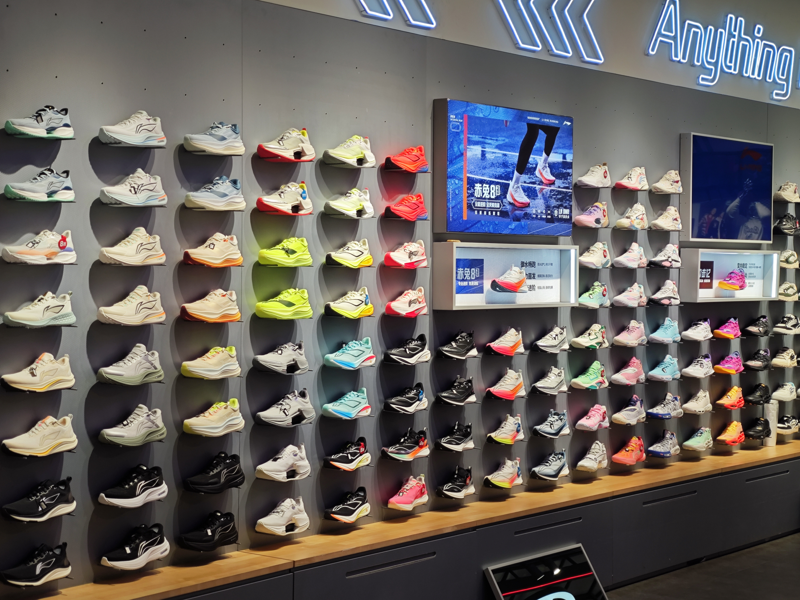

In [7]:
# @title 上传图片
from google.colab import files
from IPython.display import display
from PIL import Image as PILImage

uploaded_images = files.upload()
if len(uploaded_images) != 1:
    raise ValueError("请选择且只选择一张图片")
image_name, image_bytes = next(iter(uploaded_images.items()))
IMAGE_PATH = DEPLOYMENT_DIR / "input" / Path(image_name).name
IMAGE_PATH.parent.mkdir(exist_ok=True)
IMAGE_PATH.write_bytes(image_bytes)
del image_bytes, uploaded_images
with PILImage.open(IMAGE_PATH) as image:
    print("Stored image size (W,H):", image.size)
    preview = image.copy()
    preview.thumbnail((800, 800))
    display(preview)


## 6. 推理、编号展示，并自动保存到 Drive

| category | 选路 | 示例 |
|---|---:|---|
| concept | text_type=1 | shoe |
| simple | text_type=2 | the red shoe in the top row |
| complex | text_type=4 | the red item in the top row worn on feet while running |

`auto` 在原生 BF16 可用时使用 BF16，否则 FP16。此次运行记录只验证了 A100/BF16 的简单指令；其余路径的效果仍需测试。

编号按保存的实例顺序从 1 开始，框、掩码颜色、图下方分数与 JSON 中的 `instance_id` 一一对应。置信度是模型匹配分数，不代表已经校准的正确率。空预测会保留原图并显示空结果提示。

**本单元格结束时自动保存**结果 ZIP 至 Drive，包括编号总览图、原尺寸叠加图、各实例掩码、JSON、GPU 环境、实际 Git 提交、权重审查和日志。

{
  "gpu": "Tesla T4",
  "total_gib": 14.56317138671875,
  "free_gib": 14.45880126953125,
  "precision": "fp16",
  "torch": "2.7.1+cu126"
}
Using adapter text encoder with config: {'adapter_dim': 64, 'adapter_heads': 4, 'adapter_scale': 1.0}
Using adapter text encoder with config: {'adapter_dim': 64, 'adapter_heads': 4, 'adapter_scale': 1.0}
  Loaded 3385 weights, 0 missing
  Freeze mode: 1397 params frozen, 1956 trainable
  Skipping Adapter initialization (using checkpoint weights)
Saved 3 instances to /content/sam3i-results/2bed84be0270
{
  "git_commit": "35d4550346eab2a1613f15f9143c572580b097dd",
  "gpu": "Tesla T4",
  "precision": "fp16",
  "category": "simple",
  "threshold": 0.4,
  "instances": 3,
  "elapsed_seconds_including_model_load": 58.17881800199996,
  "peak_pytorch_allocated_gib": 7.635556697845459,
  "confidence_by_instance": [
    {
      "instance_id": 1,
      "score": 0.70361328125
    },
    {
      "instance_id": 2,
      "score": 0.56689453125
    },
    {
      "

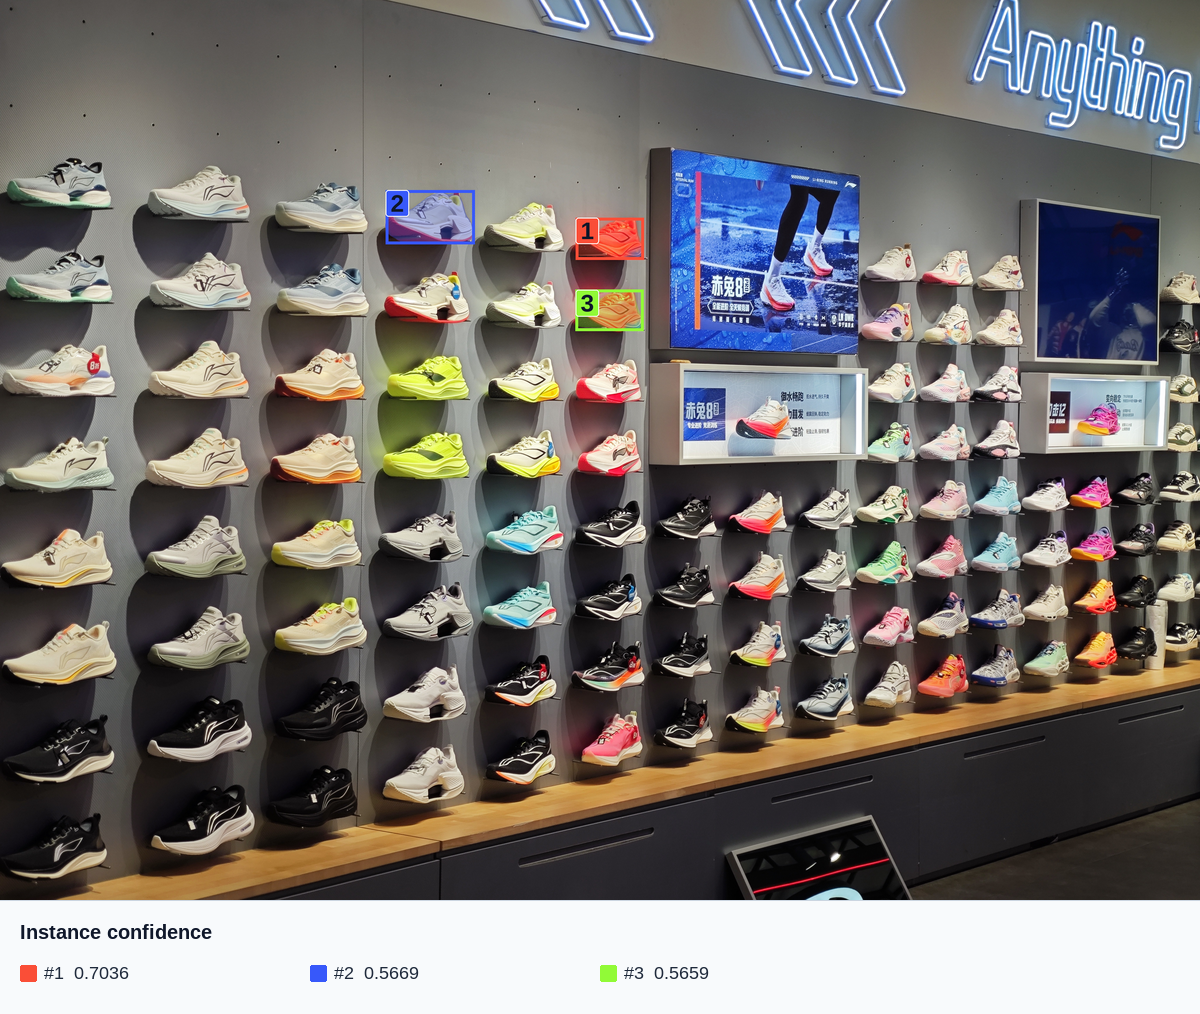

Saved to Drive: /content/drive/MyDrive/SAM3-I/results/2bed84be0270.zip


In [9]:
# @title 单图推理、展示与自动保存
PROMPT = "the red shoe in the top row" # @param {type:"string"}
CATEGORY = "simple" # @param ["concept", "simple", "complex"]
THRESHOLD = 0.4 # @param {type:"number"}
PRECISION = "auto" # @param ["auto", "bf16", "fp16", "fp32"]

OUTPUT = Path("/content/sam3i-results") / uuid.uuid4().hex[:12]
run_logged(RUN + [
    str(REPO / "scripts/colab_single_image.py"),
    "--checkpoint", str(CHECKPOINT), "--image", str(IMAGE_PATH),
    "--prompt", PROMPT, "--category", CATEGORY,
    "--threshold", str(THRESHOLD), "--precision", PRECISION,
    "--output-dir", str(OUTPUT),
], LOGS / f"inference-{OUTPUT.name}.log", env=RUN_ENV)
result, result_figure = render_saved_results(
    OUTPUT, IMAGE_PATH, SOURCE_INFO, render_overlay, render_result_figure,
)
summary = {
    "git_commit": SOURCE_INFO["git_commit"],
    "gpu": json.loads(ENVIRONMENT_PATH.read_text())["gpu"],
    "precision": result["precision"], "category": result["category"],
    "threshold": result["threshold"], "instances": result["num_instances"],
    "elapsed_seconds_including_model_load": result["elapsed_seconds"],
    "peak_pytorch_allocated_gib": result["peak_cuda_allocated_gib"],
    "confidence_by_instance": [
        {"instance_id": prediction["instance_id"], "score": prediction["score"]}
        for prediction in result["predictions"]
    ],
}
print(json.dumps(summary, ensure_ascii=False, indent=2))
# Keep full figure height so a multi-row confidence panel remains legible.
display(result_figure)
RESULT_ZIP, SAVED_RESULT = archive_run(
    OUTPUT, SOURCE_INFO, AUDIT_PATH, LOGS, ENVIRONMENT_PATH, DRIVE_RESULTS,
)


## 7. 下载结果（可选）

结果已在上一步自动保存到 Drive；本步骤只下载到电脑。

In [ ]:
# @title 下载结果 ZIP
print("Drive:", SAVED_RESULT)
files.download(str(RESULT_ZIP))


展示图 `result_figure.png` 含下方置信度面板；`overlay.png` 保持原图尺寸；`result.json` 记录每个编号的 `score`、`box_xyxy`、掩码文件及 RLE。GitHub 的实际提交号与 notebook 展示代码哈希一起保存，便于复核。

资源说明见 [Colab FAQ](https://research.google.com/colaboratory/faq.html)、[Colab I/O](https://colab.research.google.com/notebooks/io.ipynb)、[uv 锁文件](https://docs.astral.sh/uv/concepts/projects/sync/)、[PyTorch AMP](https://docs.pytorch.org/docs/2.7/amp.html)。